# Лабораторна робота №6 - Індивідуальне завдання
## Дискретна нейронна мережа Хопфілда для розпізнавання літер

**Виконавець:** Родіон Остапенко.

**Завдання (п. 3.1-3.2):**

1. Навчити дискретну мережу Хопфілда розпізнаванню **трьох різних літер** свого імені (*Родіон*). Обґрунтувати вибір: **числа нейронів** мережі; **способу кодування** елементів чорно-білих зображень; **алгоритму навчання** мережі.
2. Дослідити можливості мережі щодо розпізнавання **спотворених** зображень.

**Структура звіту (п. 4):** тема лабораторних занять; індивідуальне завдання; результати виконання пунктів завдання; розгорнутий висновок (див. розділ 7).

## 0. Середовище та допоміжні функції

Зображення зберігаються як бінарні матриці $\{0,1\}$ (для візуалізації), а в мережу подаються **біполярні** вектори $x\in\{-1,+1\}^n$ (чорний піксель $=+1$, білий $=-1$). Відстань Хеммінга - кількість позицій, у яких два вектори відрізняються.

In [31]:
import itertools
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

np.set_printoptions(precision=3, suppress=True, linewidth=140)
pd.set_option('display.precision', 3)
pd.set_option('display.width', 160)
plt.rcParams['font.family'] = 'DejaVu Sans'   # кирилиця
plt.rcParams['figure.dpi'] = 100

SEED = 20
print('NumPy:', np.__version__, '| Готово до роботи')

NumPy: 2.4.2 | Готово до роботи


In [32]:
def to_bipolar(x01):
    # {0,1} -> {-1,+1}
    return 2 * np.asarray(x01, dtype=int) - 1

def to_binary(xb):
    # {-1,+1} -> {0,1}
    return (np.asarray(xb, dtype=int) + 1) // 2

def hamming_distance(a, b):
    # Кількість позицій, у яких a і b відрізняються
    return int(np.sum(np.asarray(a) != np.asarray(b)))

def flip_pixels(x, k, rng):
    # Інвертує k випадкових різних пікселів біполярного вектора x
    y = np.asarray(x).copy()
    if k > 0:
        idx = rng.choice(len(y), size=k, replace=False)
        y[idx] *= -1
    return y

def show_images(images, titles, suptitle='', ncols=None, figsize_per=(1.9, 2.5), highlight=None):
    # Малює набір матриць 0/1 у вигляді сітки. highlight - список True/False (рамка зелена/червона).
    k = len(images)
    ncols = ncols or k
    nrows = int(np.ceil(k / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_per[0] * ncols, figsize_per[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        if i >= k:
            ax.axis('off'); continue
        mat = np.asarray(images[i])
        ax.imshow(mat, cmap='Greys', vmin=0, vmax=1, interpolation='nearest')
        ax.set_title(titles[i], fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        for r in np.arange(-.5, mat.shape[0], 1): ax.axhline(r, color='lightgray', lw=.5)
        for c in np.arange(-.5, mat.shape[1], 1): ax.axvline(c, color='lightgray', lw=.5)
        if highlight is not None:
            color = 'tab:green' if highlight[i] else 'tab:red'
            for s in ax.spines.values():
                s.set_edgecolor(color); s.set_linewidth(2.5)
    if suptitle: fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()

## 1. Вибір літер, числа нейронів, кодування та алгоритму навчання

### 1.1. Число нейронів $n$

Вибір $n$ визначається ємністю пам'яті: для некорельованих випадкових образів мережа з правилом Гебба зберігає надійно не більше

$$m_{\max}\approx 0{,}138\,n$$

образів (за більшої кількості виникає багато хибних атракторів). Нам потрібно $m=3$ літери, тобто $n\ge 3/0{,}138\approx 22$. Реальні літери корельовані, тому потрібен запас.

* **$5\times5=25$ пікселів** - формально проходить за ємністю, але літери надто схематичні, а корельованість образів зростає.
* **$7\times5=35$ пікселів** - $m_{\max}\approx 4{,}8$, тобто запас у $\approx1{,}6$ рази над потрібними трьома літерами; літери мають звичну форму.

Тому вибираємо растр **$7\times5$, $n=35$ нейронів**

### 1.2. Вибір трьох літер імені

Якість запам'ятовування в мережі Хопфілда визначається **кореляцією** образів: перехресна завада між образами $\mu$ і $\nu$ пропорційна нормованому скалярному добутку $\frac1n\langle\xi^\mu,\xi^\nu\rangle=1-\frac{2d_H}{n}$. Важливі **обидва знаки**: сильна додатна кореляція (малі $d_H$) і сильна від'ємна (великі $d_H$, образ майже збігається з негативом іншого). Тому критерій вибору - **мінімум $\max|\text{кореляція}|$** серед трійок, а при рівності - максимум мінімальної відстані Хеммінга.

In [33]:
FONT_7X5 = {
 'Р': ['11110','10001','10001','11110','10000','10000','10000'],
 'О': ['01110','10001','10001','10001','10001','10001','01110'],
 'Д': ['01111','01001','01001','01001','01001','11111','10001'],
 'І': ['01110','00100','00100','00100','00100','00100','01110'],
 'Н': ['10001','10001','10001','11111','10001','10001','10001'],
 'С': ['01111','10000','10000','10000','10000','10000','01111'],
 'Т': ['11111','00100','00100','00100','00100','00100','00100'],
 'А': ['00100','01010','10001','10001','11111','10001','10001'],
 'П': ['11111','10001','10001','10001','10001','10001','10001'],
 'Е': ['11111','10000','10000','11110','10000','10000','11111'],
 'К': ['10001','10010','10100','11000','10100','10010','10001'],
}
H, W = 7, 5
N = H * W

def glyph(letter):
    return np.array([[int(c) for c in row] for row in FONT_7X5[letter]], dtype=int)

for ch, rows_ in FONT_7X5.items():
    assert len(rows_) == H and all(len(r) == W and set(r) <= {'0', '1'} for r in rows_), ch

NAME = 'РОДІОН'
NAME_LETTERS = list(dict.fromkeys(NAME))
print('Унікальні літери імені:', NAME_LETTERS, '| n =', N, '| 0,138·n =', round(0.138 * N, 2))

rows = []
for tri in itertools.combinations(NAME_LETTERS, 3):
    P_ = np.array([to_bipolar(glyph(c).ravel()) for c in tri])
    C_ = P_ @ P_.T / N
    pairs = [(0, 1), (0, 2), (1, 2)]
    dH = [hamming_distance(P_[i], P_[j]) for i, j in pairs]
    W_ = P_.T @ P_ / N; np.fill_diagonal(W_, 0)
    rows.append({'Літери': ''.join(tri),
                 'd_H (пари)': '/'.join(map(str, dH)),
                 'min d_H': min(dH),
                 'max |кореляція|': max(abs(C_[i, j]) for i, j in pairs)})
SEL_TABLE = (pd.DataFrame(rows)
             .sort_values(['max |кореляція|', 'min d_H'], ascending=[True, False])
             .reset_index(drop=True))
display(SEL_TABLE)

LETTERS = list(SEL_TABLE.loc[0, 'Літери'])
print('\nОбрані літери:', LETTERS)

Унікальні літери імені: ['Р', 'О', 'Д', 'І', 'Н'] | n = 35 | 0,138·n = 4.83


,Літери,d_H (пари),min d_H,max |кореляція|
0,РДІ,18/18/22,18,0.257
1,ОДІ,17/15/22,15,0.257
2,ОДН,17/13/16,13,0.257
3,РОД,11/18/17,11,0.371
4,РОІ,11/18/15,11,0.371
5,ДІН,22/16/26,16,0.486
6,ОІН,15/13/26,13,0.486
7,РОН,11/8/13,8,0.543
8,РДН,18/8/16,8,0.543
9,РІН,18/8/26,8,0.543



Обрані літери: ['Р', 'Д', 'І']


n = 35 нейронів, m = 3 образи; m/n = 0.086 (поріг ємності ~0.138)
Матриця відстаней Хеммінга між еталонами:
[[ 0 18 18]
 [18  0 22]
 [18 22  0]]


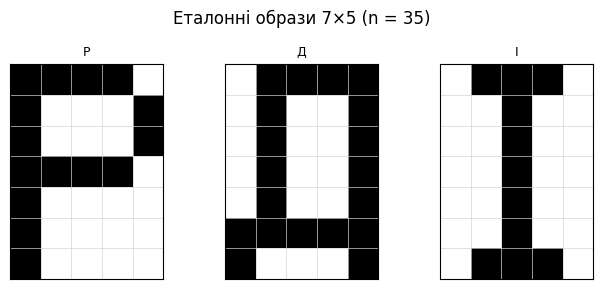

In [34]:
M = len(LETTERS)
IMAGES = np.stack([glyph(c) for c in LETTERS])
P = to_bipolar(IMAGES.reshape(M, N))
assert len({tuple(r) for r in P}) == M

D_PAIR = (P[:, None, :] != P[None, :, :]).sum(-1)
print(f'n = {N} нейронів, m = {M} образи; m/n = {M / N:.3f} (поріг ємності ~0.138)')
print('Матриця відстаней Хеммінга між еталонами:'); print(D_PAIR)

show_images(IMAGES, LETTERS, f'Еталонні образи 7×5 (n = {N})', ncols=M, figsize_per=(2.2, 2.9))

### 1.3. Кодування елементів зображення

Вибираємо **біполярне кодування**: чорний піксель $\to +1$, білий $\to -1$. Обґрунтування:

* Нейрон Хопфілда має **два стани $\pm1$** і активацію $\operatorname{sign}$; саме біполярне кодування узгоджене з моделлю і з енергетичною функцією.
* Правило Гебба $w_{ij}=\frac1n\sum_\mu\xi^\mu_i\xi^\mu_j$ при $\pm1$ дає **$+$ при збігу і $-$ при розбіжності** станів пікселів: мережа запам'ятовує і кореляцію, і *антикореляцію*. При кодуванні $\{0,1\}$ добуток $\xi_i\xi_j=1$ лише коли **обидва** пікселі чорні, а білий фон не несе жодної інформації; усі ваги стають **невід'ємними** (немає гальмування), і мережа «затоплює» зображення чорним.
* При $\pm1$ середнє значення образу близьке до нуля, тому поріг нейрона можна взяти $\theta=0$ без додаткових зміщень.

Перевіримо це експериментом: застосуємо правило Гебба до кодування $\{0,1\}$ (порогова активація $x_i=1$ при $\sum_j w_{ij}x_j>0$) і подивимось на відновлення літер із трьома спотвореними пікселями.

Ваги Гебба на {0,1}: мінімальна вага = 0.0 (усі невід'ємні, гальмування немає)
Частка правильних відновлень при 3 спотворених пікселях (кодування {0,1}): 0%


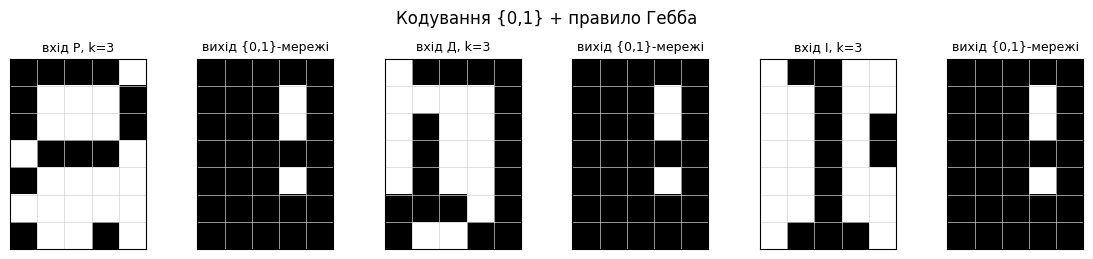

In [35]:
def hebb_01_recall(P01, x01, rng, max_sweeps=50):
    # Мережа Хопфілда з Геббом, але на кодуванні {0,1}: x_i = 1, якщо (W x)_i > 0, інакше 0
    n = P01.shape[1]
    Wm = P01.T @ P01 / n
    np.fill_diagonal(Wm, 0)
    x = x01.copy()
    for _ in range(max_sweeps):
        changed = False
        for i in rng.permutation(n):
            new = 1 if Wm[i] @ x > 0 else 0
            if new != x[i]:
                x[i] = new; changed = True
        if not changed:
            break
    return x

P01 = IMAGES.reshape(M, N)
rng_c = np.random.default_rng(SEED)
res01, ok01, imgs, titles = [], 0, [], []
for i in range(M):
    for _ in range(100):
        x0 = to_binary(flip_pixels(P[i], 3, rng_c))
        xf = hebb_01_recall(P01, x0, rng_c)
        ok01 += np.array_equal(xf, P01[i])
    x0 = to_binary(flip_pixels(P[i], 3, rng_c)); xf = hebb_01_recall(P01, x0, rng_c)
    imgs += [x0.reshape(H, W), xf.reshape(H, W)]
    titles += [f'вхід {LETTERS[i]}, k=3', 'вихід {0,1}-мережі']

print('Ваги Гебба на {0,1}: мінімальна вага =', (P01.T @ P01 / N).min(), '(усі невід\'ємні, гальмування немає)')
print(f'Частка правильних відновлень при 3 спотворених пікселях (кодування {{0,1}}): {ok01 / (100 * M):.0%}')
show_images(imgs, titles, 'Кодування {0,1} + правило Гебба', ncols=6, figsize_per=(1.9, 2.6))

### 1.4. Алгоритм навчання

Для дискретної мережі Хопфілда розглядаємо два **неітераційні** (one-shot) правила:

1. **Правило Гебба (зовнішній добуток):**

$$W=\frac1n\sum_{\mu=1}^{m}\xi^{\mu}(\xi^{\mu})^{T},\qquad w_{ii}=0 .$$

   Просте, локальне (вага залежить лише від двох нейронів), симетричне, ваги обчислюються за один прохід.
2. **Проекційне (псевдообернене) правило:** $W=\Xi^{T}(\Xi\,\Xi^{T})^{-1}\Xi$, де $\Xi$ - матриця образів $m\times n$. Прибирає перехресні завади для лінійно незалежних образів і дає ємність до $\sim n$, але потребує **обернення матриці** і є нелокальним.

**Вибір - правило Гебба**: воно є класичним правилом навчання дискретної мережі Хопфілда, для $m=3$ при $n=35$ ($m/n\approx0{,}09$) воно задовольняє умову ємності, а перевірка нижче покаже, що всі три еталони є стійкими станами. Проекційне правило використаємо як **еталон для порівняння** (розділи 3, 5, 6). Поріг усіх нейронів $\theta_i=0$.

**Умова стійкості еталона за Гебба.** При $w_{ii}=0$: $W=\frac1n\sum_\nu\xi^\nu\xi^{\nu T}-\frac mn I$, тому локальне поле на еталоні $\xi^\mu$

$$h^{\mu}_i=\bigl(W\xi^{\mu}\bigr)_i=\Bigl(1-\frac mn\Bigr)\xi^{\mu}_i+\underbrace{\frac1n\sum_{\nu\neq\mu}\xi^{\nu}_i\,\langle\xi^{\nu},\xi^{\mu}\rangle}_{\text{перехресна завада}} .$$

Еталон є нерухомою точкою, якщо $\xi^\mu_ih^\mu_i>0$ для всіх $i$. Величину $\min_i\xi^\mu_ih^\mu_i$ називаємо **запасом стійкості**.

## 2. Модель мережі та динаміка

Стан мережі $x\in\{-1,+1\}^n$. Вхід нейрона $i$: $u_i=\sum_{j}w_{ij}x_j$ (поріг $\theta_i=0$), активація - знак:

$$x_i\leftarrow\operatorname{sign}(u_i),\qquad \operatorname{sign}(0):=x_i\ \text{(стан не змінюється)}.$$

**Режими оновлення.**

* **Асинхронний** - нейрони оновлюються по одному у випадковому порядку (один «прохід» = $n$ оновлень). Для симетричної матриці з нульовою діагоналлю **функція енергії**

$$E(x)=-\tfrac12\,x^{T}Wx$$

  не зростає: при зміні лише $x_i$ маємо $\Delta E=-\Delta x_i\,u_i\le0$. Оскільки $E$ обмежена знизу на скінченній множині станів, мережа **за скінченне число кроків потрапляє в нерухому точку** (локальний мінімум енергії).
* **Синхронний** - усі нейрони оновлюються одночасно. Збіжність до нерухомої точки вже не гарантується: можливі **цикли довжини 2**. Цей режим порівняємо з асинхронним експериментально.

Розпізнавання - це релаксація: початковий стан $x(0)$ = (спотворене) зображення, кінцевий стан - найближчий атрактор.

In [36]:
class HopfieldNet:
    # Дискретна мережа Хопфілда: бінарні нейрони, поріг 0, нульова діагональ ваг

    def __init__(self, rule='hebb'):
        assert rule in ('hebb', 'pinv')
        self.rule = rule

    def fit(self, P):
        # Навчання за один прохід: W обчислюється безпосередньо за еталонами P (m, n)
        P = np.asarray(P, dtype=float)
        self.P = P
        self.m, self.n = P.shape
        if self.rule == 'hebb':
            Wm = P.T @ P / self.n
        else:
            Wm = P.T @ np.linalg.pinv(P @ P.T) @ P
        Wm = Wm.copy()
        np.fill_diagonal(Wm, 0.0)
        self.W = Wm
        return self

    def energy(self, x):
        x = np.asarray(x, dtype=float)
        return float(-0.5 * x @ self.W @ x)

    def margins(self):
        # Запас стійкості кожного еталона: min_i xi_i * h_i, h = W xi
        return (self.P * (self.P @ self.W)).min(axis=1)

    def recall(self, x0, rng=None, mode='async', max_sweeps=100):
        # Релаксація до нерухомої точки. Повертає словник зі станом, енергіями та станами по проходах
        x = np.asarray(x0, dtype=float).copy()
        if mode == 'async':
            rng = rng or np.random.default_rng(0)
            E = [self.energy(x)]
            states = [x.copy()]
            sweeps = 0
            converged = False
            for sweep in range(1, max_sweeps + 1):
                changed = False
                for i in rng.permutation(self.n):
                    h = self.W[i] @ x
                    new = x[i] if h == 0 else (1.0 if h > 0 else -1.0)
                    if new != x[i]:
                        E.append(E[-1] - (new - x[i]) * h)
                        x[i] = new
                        changed = True
                states.append(x.copy())
                if not changed:
                    converged = True
                    break
                sweeps = sweep
            return dict(x=x, E=np.array(E), states=states, sweeps=sweeps,
                        converged=converged, kind='fixed' if converged else 'none')
        else:
            prev, kind = None, 'none'
            states = [x.copy()]
            steps = 0
            for t in range(1, max_sweeps + 1):
                h = self.W @ x
                new = np.where(h > 0, 1.0, np.where(h < 0, -1.0, x))
                if np.array_equal(new, x):
                    kind = 'fixed'; break
                if prev is not None and np.array_equal(new, prev):
                    kind = 'cycle2'; break
                prev, x = x, new
                states.append(x.copy())
                steps = t
            return dict(x=x, E=np.array([self.energy(s) for s in states]), states=states,
                        sweeps=steps, converged=(kind == 'fixed'), kind=kind)


def outcome(x, P, target):
    # Класифікація результату релаксації відносно еталонів
    if np.array_equal(x, P[target]):
        return 'ok'
    if any(np.array_equal(x, P[k]) for k in range(len(P))):
        return 'other'          # збіглося з іншою літерою
    if any(np.array_equal(x, -P[k]) for k in range(len(P))):
        return 'inv'            # інверсія (негатив) якоїсь літери
    return 'spur'               # хибний атрактор

def make_inputs(P, k, trials, rng):
    return [(i, flip_pixels(P[i], k, rng)) for i in range(len(P)) for _ in range(trials)]

def evaluate(net, inputs, rng, mode='async'):
    res = []
    for target, x in inputs:
        r = net.recall(x, rng=rng, mode=mode)
        res.append('cycle' if r['kind'] == 'cycle2' else outcome(r['x'], net.P, target))
    return res

## 3. Навчання мережі

### 3.1. Побудова мережі (п. 3.1 завдання)

Навчання зводиться до запису еталонів у ваги: $W=\frac1n\sum_\mu\xi^\mu\xi^{\mu T}$, $w_{ii}=0$. Побудуємо мережу за правилом Гебба (основна) і проекційним правилом (для порівняння), перевіримо симетричність $W$, нульову діагональ, **стійкість еталонів** та їхні енергії.

In [37]:
net = HopfieldNet('hebb').fit(P)
net_pinv = HopfieldNet('pinv').fit(P)

print(f'Матриця ваг W: {net.W.shape}, симетрична: {np.allclose(net.W, net.W.T)}, діагональ нульова: {np.allclose(np.diag(net.W), 0)}')
print(f'Число незалежних ваг n(n-1)/2 = {N * (N - 1) // 2}')
print(f'Ваги Гебба приймають значення: {np.unique(np.round(net.W, 4))}')

# запас стійкості та енергія еталонів
tab = pd.DataFrame({
    'Запас стійкості (Гебб)': net.margins(),
    'Запас стійкості (псевдооберн.)': net_pinv.margins(),
    'Енергія': [net.energy(p) for p in P],
}, index=[f'еталон {c}' for c in LETTERS])
display(tab)
assert (net.margins() > 0).all(), 'не всі еталони стійкі'

# кожен еталон та його негатив - нерухомі точки; перевірка самовідновлення
rng_s = np.random.default_rng(SEED)
for i in range(M):
    for sgn in (+1, -1):
        r = net.recall(sgn * P[i], rng_s)
        assert np.array_equal(r['x'], sgn * P[i]) and r['sweeps'] == 0

Матриця ваг W: (35, 35), симетрична: True, діагональ нульова: True
Число незалежних ваг n(n-1)/2 = 595
Ваги Гебба приймають значення: [-0.086 -0.029  0.     0.029  0.086]


,Запас стійкості (Гебб),Запас стійкості (псевдооберн.),Енергія
еталон Р,0.857,0.89,-16.029
еталон Д,0.629,0.89,-17.171
еталон І,0.629,0.89,-17.171


Вхід: Д + 7 помилок (d_H до еталона = 7); проходів: 1; результат: ok; E: -7.23 -> -17.17


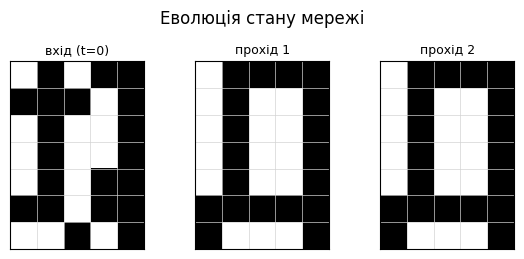

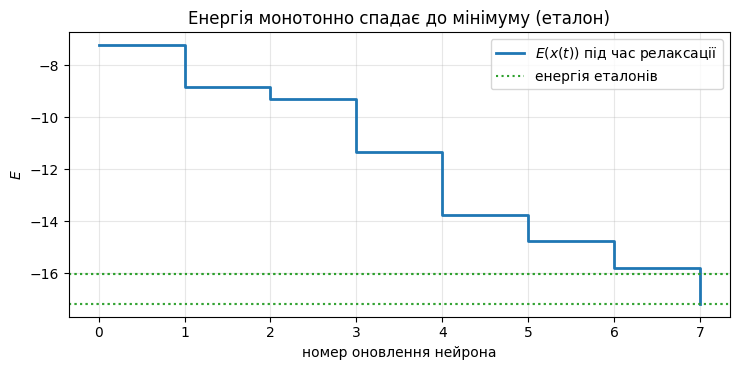

In [38]:
# Приклад релаксації: літера Д з 7 спотвореними пікселями
t_idx = LETTERS.index('Д')
rng_demo = np.random.default_rng(3)
x_demo = flip_pixels(P[t_idx], 7, rng_demo)
r = net.recall(x_demo, np.random.default_rng(5))
print(f'Вхід: Д + 7 помилок (d_H до еталона = {hamming_distance(x_demo, P[t_idx])}); '
      f'проходів: {r["sweeps"]}; результат: {outcome(r["x"], P, t_idx)}; E: {r["E"][0]:.2f} -> {r["E"][-1]:.2f}')

states = r['states']
show_images([to_binary(s).reshape(H, W) for s in states],
            ['вхід (t=0)'] + [f'прохід {t}' for t in range(1, len(states))],
            'Еволюція стану мережі', ncols=len(states), figsize_per=(1.9, 2.6))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.step(range(len(r['E'])), r['E'], where='post', lw=2, label='$E(x(t))$ під час релаксації')
for i in range(M):
    ax.axhline(net.energy(P[i]), color='tab:green', ls=':', alpha=.8)
ax.axhline(net.energy(P[0]), color='tab:green', ls=':', label='енергія еталонів')
ax.set_xlabel('номер оновлення нейрона'); ax.set_ylabel('$E$'); ax.grid(alpha=.3); ax.legend()
ax.set_title('Енергія монотонно спадає до мінімуму (еталон)')
plt.tight_layout(); plt.show()
assert np.all(np.diff(r['E']) <= 1e-12)

## 4. Розпізнавання спотворених зображень (п. 3.2 завдання)

Досліджуємо два типи спотворень:

1. **Випадковий шум** - інверсія $k$ випадкових пікселів. Для кожного $k=0,\dots,17$ виконуємо по 200 випробувань на літеру (метод Монте-Карло) і підраховуємо частку випадків, коли мережа **відновила саме еталон**. Порівнюємо правило Гебба (асинхронний і синхронний режими) та проекційне правило.
2. **Структурні спотворення** - зсув на 1 піксель, часткове стирання. Мережа порівнює піксель із пікселем, тому **не інваріантна до зсуву**; стирання ж є типовою задачею *асоціативної пам'яті* (відновлення за фрагментом).

In [39]:
K_RANGE = list(range(0, 18))
TRIALS = 200
rng_in = np.random.default_rng(SEED)
rng_ev = np.random.default_rng(SEED + 2)

rows, breakdown, per_letter = [], {}, {}
for k in K_RANGE:
    inputs = make_inputs(P, k, TRIALS, rng_in)
    targets = np.array([t for t, _ in inputs])
    r_h = np.array(evaluate(net, inputs, rng_ev))
    r_p = np.array(evaluate(net_pinv, inputs, rng_ev))
    r_s = np.array(evaluate(net, inputs, rng_ev, mode='sync'))
    rows.append({'k': k, 'k/n': k / N,
                 'Гебб, асинхронний': np.mean(r_h == 'ok'),
                 'Гебб, синхронний': np.mean(r_s == 'ok'),
                 'Псевдообернене, асинхр.': np.mean(r_p == 'ok')})
    per_letter[k] = [np.mean(r_h[targets == i] == 'ok') for i in range(M)]
    breakdown[k] = {o: np.mean(r_h == o) for o in ['ok', 'other', 'inv', 'spur']}
    breakdown[k]['цикл (sync)'] = np.mean(r_s == 'cycle')
NOISE_TABLE = pd.DataFrame(rows).set_index('k')
display(NOISE_TABLE.T.round(3).iloc[:, ::1])

k,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
k/n,0.0,0.029,0.057,0.086,0.114,0.143,0.171,0.200,0.229,0.257,0.286,0.314,0.343,0.371,0.400,0.429,0.457,0.486
"Гебб, асинхронний",1.0,1.000,1.000,1.000,1.000,1.000,0.997,0.982,0.953,0.925,0.875,0.775,0.707,0.518,0.440,0.288,0.147,0.040
"Гебб, синхронний",1.0,1.000,1.000,1.000,1.000,1.000,0.998,0.995,0.980,0.957,0.942,0.815,0.780,0.578,0.467,0.235,0.078,0.008
"Псевдообернене, асинхр.",1.0,1.000,1.000,1.000,1.000,1.000,0.998,0.993,0.967,0.947,0.918,0.812,0.753,0.582,0.432,0.288,0.140,0.050


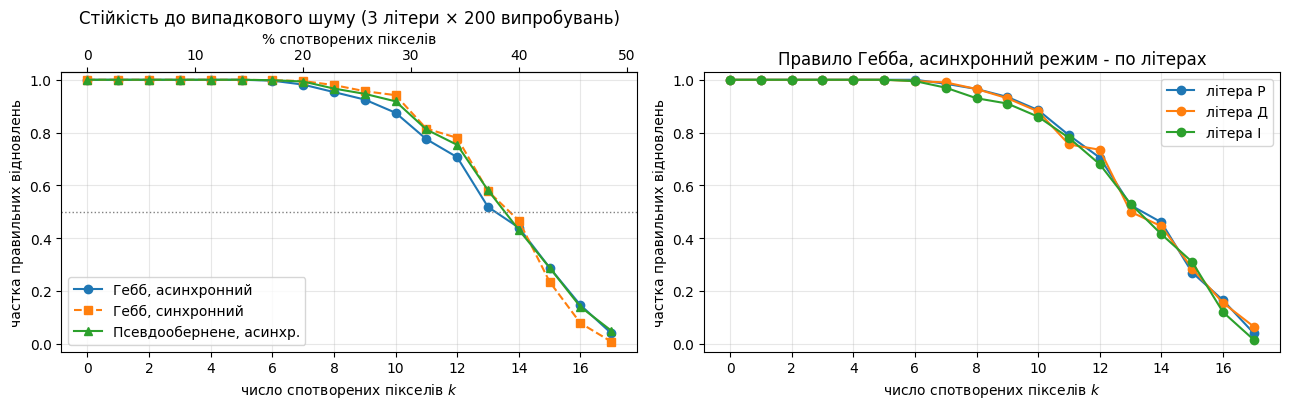

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
for col, st in [('Гебб, асинхронний', 'o-'), ('Гебб, синхронний', 's--'), ('Псевдообернене, асинхр.', '^-')]:
    ax.plot(NOISE_TABLE.index, NOISE_TABLE[col], st, label=col)
ax.axhline(0.5, color='gray', ls=':', lw=1)
ax.set_xlabel('число спотворених пікселів $k$'); ax.set_ylabel('частка правильних відновлень')
ax.set_title('Стійкість до випадкового шуму (3 літери × 200 випробувань)')
ax.set_xticks(K_RANGE[::2]); ax.set_ylim(-.03, 1.03); ax.grid(alpha=.3); ax.legend()
sec = ax.secondary_xaxis('top', functions=(lambda k: 100 * k / N, lambda p: p * N / 100))
sec.set_xlabel('% спотворених пікселів')

ax = axes[1]
for i, c in enumerate(LETTERS):
    ax.plot(K_RANGE, [per_letter[k][i] for k in K_RANGE], 'o-', label=f'літера {c}')
ax.set_xlabel('число спотворених пікселів $k$'); ax.set_ylabel('частка правильних відновлень')
ax.set_title('Правило Гебба, асинхронний режим - по літерах')
ax.set_xticks(K_RANGE[::2]); ax.set_ylim(-.03, 1.03); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

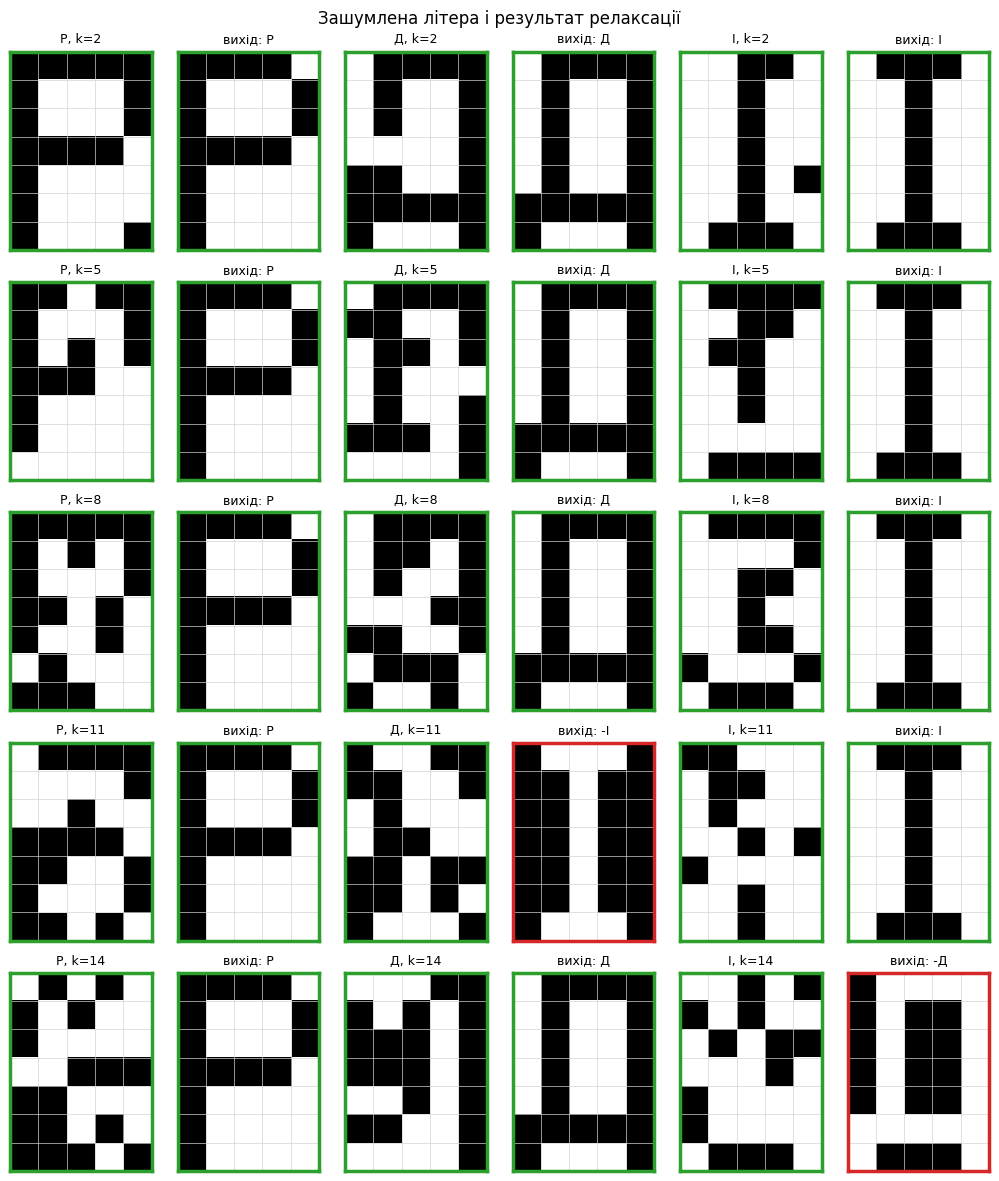

In [41]:
# Приклади зашумлених літер та відповідь мережі
def classify(x, P, labels):
    for k in range(len(P)):
        if np.array_equal(x, P[k]): return f'еталон {labels[k]}'
    for k in range(len(P)):
        if np.array_equal(x, -P[k]): return f'негатив {labels[k]}'
    return 'хибний атрактор'

rng_ex = np.random.default_rng(11)
imgs, titles, ok_flags = [], [], []
for k in [2, 5, 8, 11, 14]:
    for idx in range(M):
        x = flip_pixels(P[idx], k, rng_ex)
        r = net.recall(x, np.random.default_rng(k * 10 + idx))
        o = outcome(r['x'], P, idx)
        lab = classify(r['x'], P, LETTERS).replace('еталон ', '').replace('негатив ', '-') if o != 'spur' else 'хибний'
        imgs += [to_binary(x).reshape(H, W), to_binary(r['x']).reshape(H, W)]
        titles += [f'{LETTERS[idx]}, k={k}', f'вихід: {lab}']
        ok_flags += [True, o == 'ok']
show_images(imgs, titles, 'Зашумлена літера і результат релаксації',
            ncols=6, figsize_per=(1.7, 2.4), highlight=ok_flags)

,Р,Д,І
зсув вправо на 1,Д (8%),І (0%),хибний (44%)
зсув вниз на 1,хибний (28%),хибний (16%),І (68%)
стерто верхній рядок,Р (100%),Д (100%),І (100%)
стерто нижній рядок,Р (100%),Д (100%),І (100%)
стерто правий стовпець,Р (100%),Д (100%),І (100%)
стерто верхні 3 рядки,Р (100%),Д (100%),І (100%)
стерто нижні 3 рядки,Р (100%),Д (72%),І (100%)


Середня частка правильних відповідей: {'зсув вправо на 1': '17%', 'зсув вниз на 1': '37%', 'стерто верхній рядок': '100%', 'стерто нижній рядок': '100%', 'стерто правий стовпець': '100%', 'стерто верхні 3 рядки': '100%', 'стерто нижні 3 рядки': '91%'}
d_H(спотворений вхід, еталон): {'зсув вправо на 1': [16, 17, 14], 'зсув вниз на 1': [15, 12, 7], 'стерто верхній рядок': [4, 4, 3], 'стерто нижній рядок': [1, 2, 3], 'стерто правий стовпець': [2, 7, 0], 'стерто верхні 3 рядки': [8, 8, 5], 'стерто нижні 3 рядки': [3, 9, 5]}


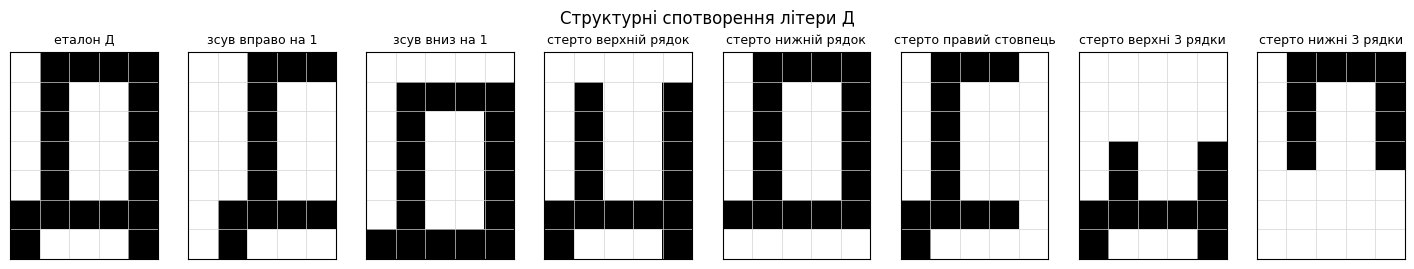

In [42]:
# Структурні спотворення: зсув, стирання
def shift(img, dr=0, dc=0):
    out = np.zeros_like(img)
    h, w = img.shape
    src = img[max(0, -dr):h - max(0, dr), max(0, -dc):w - max(0, dc)]
    out[max(0, dr):max(0, dr) + src.shape[0], max(0, dc):max(0, dc) + src.shape[1]] = src
    return out

def erase_rows(img, rows):
    out = img.copy(); out[rows, :] = 0; return out

def erase_cols(img, cols):
    out = img.copy(); out[:, cols] = 0; return out

DISTORTIONS = {
    'зсув вправо на 1':        lambda im: shift(im, 0, 1),
    'зсув вниз на 1':          lambda im: shift(im, 1, 0),
    'стерто верхній рядок':    lambda im: erase_rows(im, [0]),
    'стерто нижній рядок':     lambda im: erase_rows(im, [H - 1]),
    'стерто правий стовпець':  lambda im: erase_cols(im, [W - 1]),
    'стерто верхні 3 рядки':   lambda im: erase_rows(im, [0, 1, 2]),
    'стерто нижні 3 рядки':    lambda im: erase_rows(im, [H - 3, H - 2, H - 1]),
}
N_ORD = 25     # кількість різних випадкових порядків оновлення нейронів

table, stat, dist_d = {}, {}, {}
for name, f in DISTORTIONS.items():
    col, correct = [], 0
    for i in range(M):
        x = to_bipolar(f(IMAGES[i]).ravel())
        rr = [net.recall(x, np.random.default_rng(SEED + s)) for s in range(N_ORD)]
        outs = [outcome(r['x'], P, i) for r in rr]
        rate = np.mean([o == 'ok' for o in outs])
        lab = Counter(classify(r['x'], P, LETTERS).replace('еталон ', '').replace('негатив ', '-') if o != 'spur' else 'хибний'
                      for r, o in zip(rr, outs)).most_common(1)[0][0]
        col.append(f'{lab} ({rate:.0%})')
        correct += rate
        dist_d[(name, i)] = hamming_distance(x, P[i])
    table[name] = col; stat[name] = correct / M
STRUCT_TABLE = pd.DataFrame(table, index=[f'{c}' for c in LETTERS]).T
display(STRUCT_TABLE)
print('Середня частка правильних відповідей:', {k: f'{v:.0%}' for k, v in stat.items()})
print('d_H(спотворений вхід, еталон):', {nm: [dist_d[(nm, i)] for i in range(M)] for nm in DISTORTIONS})

i0 = LETTERS.index('Д')
show_images([IMAGES[i0]] + [f(IMAGES[i0]) for f in DISTORTIONS.values()],
            ['еталон Д'] + list(DISTORTIONS), 'Структурні спотворення літери Д',
            ncols=8, figsize_per=(1.8, 2.7))

## 5. Звіт з лабораторної роботи

**5.1. Тема:** Дискретна нейронна мережа Хопфілда. Розпізнавання літер, стійкість до спотворень, хибні атрактори та ємність пам'яті.

**5.2. Індивідуальне завдання:** Родіон Остапенко. Навчити мережу Хопфілда розпізнаванню трьох літер імені - **Р, Д, І** (еталони - растр $7\times5$); обґрунтувати число нейронів, кодування зображень та алгоритм навчання; дослідити розпізнавання спотворених зображень.

**5.3. Результати виконання завдання:**

| Параметр | Вибір | Обґрунтування |
|---|---|---|
| Літери | **Р, Д, І** | з п'яти літер імені (Р, О, Д, І, Н) мінімальна кореляція образів: $\max\lvert\text{кор.}\rvert=0{,}257$, $d_{\min}=18$ |
| Число нейронів | $n=35$ ($7\times5$) | один нейрон на піксель; ємність $0{,}138n\approx4{,}8$ образу, потрібно $m=3$ ($m/n=0{,}086$) |
| Кодування | біполярне: чорний $=+1$, білий $=-1$ | модель $\operatorname{sign}$; Гебб кодує і кореляцію, і антикореляцію; поріг $\theta=0$. Кодування $\{0,1\}$ дало **0 %** правильних відновлень |
| Алгоритм навчання | правило Гебба $W=\frac1n\sum\xi\xi^T$, $w_{ii}=0$ | один прохід, локальне, симетричне $W$ (існує функція енергії); запас стійкості еталонів $0{,}63$-$0{,}86>0$ |
| Режим роботи | асинхронний, випадковий порядок | гарантована збіжність: $E=-\frac12x^TWx$ не зростає |

In [43]:
print('1) Вибір літер (відсортовано за критерієм):'); display(SEL_TABLE)
print('\n2) Кодування: частка правильних відновлень при k = 3 спотворених пікселях:')
display(pd.DataFrame({'Кодування': ['{0,1} (Гебб)', '±1 (Гебб)'],
                      'Правильних відновлень': [ok01 / (100 * M), NOISE_TABLE.loc[3, 'Гебб, асинхронний']]}))
print('\n3) Випадковий шум (частка правильних відновлень):'); display(NOISE_TABLE.drop(columns='k/n').T.round(3))
print('\n4) Структурні спотворення (результат і частка правильних відповідей):'); display(STRUCT_TABLE)

1) Вибір літер (відсортовано за критерієм):


,Літери,d_H (пари),min d_H,max |кореляція|
0,РДІ,18/18/22,18,0.257
1,ОДІ,17/15/22,15,0.257
2,ОДН,17/13/16,13,0.257
3,РОД,11/18/17,11,0.371
4,РОІ,11/18/15,11,0.371
5,ДІН,22/16/26,16,0.486
6,ОІН,15/13/26,13,0.486
7,РОН,11/8/13,8,0.543
8,РДН,18/8/16,8,0.543
9,РІН,18/8/26,8,0.543



2) Кодування: частка правильних відновлень при k = 3 спотворених пікселях:


,Кодування,Правильних відновлень
0,"{0,1} (Гебб)",0.0
1,±1 (Гебб),1.0



3) Випадковий шум (частка правильних відновлень):


k,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
"Гебб, асинхронний",1.0,1.0,1.0,1.0,1.0,1.0,0.997,0.982,0.953,0.925,0.875,0.775,0.707,0.518,0.440,0.288,0.147,0.040
"Гебб, синхронний",1.0,1.0,1.0,1.0,1.0,1.0,0.998,0.995,0.980,0.957,0.942,0.815,0.780,0.578,0.467,0.235,0.078,0.008
"Псевдообернене, асинхр.",1.0,1.0,1.0,1.0,1.0,1.0,0.998,0.993,0.967,0.947,0.918,0.812,0.753,0.582,0.432,0.288,0.140,0.050



4) Структурні спотворення (результат і частка правильних відповідей):


,Р,Д,І
зсув вправо на 1,Д (8%),І (0%),хибний (44%)
зсув вниз на 1,хибний (28%),хибний (16%),І (68%)
стерто верхній рядок,Р (100%),Д (100%),І (100%)
стерто нижній рядок,Р (100%),Д (100%),І (100%)
стерто правий стовпець,Р (100%),Д (100%),І (100%)
стерто верхні 3 рядки,Р (100%),Д (100%),І (100%)
стерто нижні 3 рядки,Р (100%),Д (72%),І (100%)


### **Висновок:**

* **Число нейронів.** Мережа Хопфілда має по одному нейрону на піксель, тож $n=7\times5=35$; матриця ваг $35\times35$ симетрична з нульовою діагоналлю (595 незалежних ваг). Вибір обґрунтований ємністю $\approx0{,}138\,n=4{,}8$ образу: для $m=3$ відношення $m/n=0{,}086$. Експеримент підтвердив оцінку: правилом Гебба для $m\le4$ усі еталони стійкі, для $m=5$ стійкими лишається лише 80 %, для $m=8$ - 50 %, для $m=11$ - 18 %.
* **Кодування.** Біполярне кодування ($+1/-1$) узгоджене з моделлю нейрона й правилом Гебба. Для кодування $\{0,1\}$ усі ваги Гебба невід'ємні, гальмування немає, і мережа «затоплює» зображення чорним: **0 %** правильних відновлень навіть при 3 спотворених пікселях проти **100 %** для $\pm1$.
* **Навчання.** Правило Гебба - це неітераційне обчислення $W$ за еталонами. Три літери **Р, Д, І** обрано за мінімальною кореляцією ($\max|\text{кор.}|=0{,}257$, $d_{\min}=18$ з 35 пікселів). Запас стійкості еталонів $\min_i\xi_ih_i$ дорівнює $0{,}86$ (Р), $0{,}63$ (Д), $0{,}63$ (І) - усі додатні, тож **усі три еталони та їх негативи є нерухомими точками** мережі. Проекційне правило дає запас $0{,}89$ для кожного.
* **Випадковий шум.** Для $k\le5$ спотворених пікселів (до 14 % зображення) розпізнавання **безпомилкове** (≥ 99,8 %); при $k=7$ - 99,0 %, при $k=8$ - 95,3 % (23 % пікселів), при $k=10$ - 85,7 %, при $k=12$ - 71,5 %; 50 % досягається біля $k\approx13$ (37 % пікселів), а при $k=17$ лишається лише 5,5 %. При малих $k$ помилки - це хибні атрактори, при $k\ge14$ переважають збіжність до **негатива** і до **іншої літери** (при $k=16$: 40 % і 33 %).
* **Режими та правила.** Синхронний режим на середніх $k$ дав навіть трохи кращі результати (94,2 % проти 85,7 % при $k=10$), але **не гарантує збіжності**: 0,4 % випадкових стартів завершились 2-циклом, а при $k=17$ точність впала до 0,8 %. Проекційне правило при $m=3$ лише трохи краще за Гебба на середніх $k$ (на 2-6 п.п., наприклад 91,8 % проти 85,7 % при $k=10$), а при $k\ge14$ різниці практично немає; його головна перевага проявляється з ростом $m$.
* **Структурні спотворення.** Мережа **не інваріантна до зсуву**: зсув на 1 піксель вправо дав у середньому 16 % правильних відповідей (відстань до еталона 14-17 пікселів), вниз - 45 % (літера І - 92 %, бо її зсув вниз дає лише 7 помилок). Натомість **стирання фрагмента** відновлюється добре: стирання верхнього/нижнього рядка, правого стовпця та верхніх 3 рядків - 100 %, нижніх 3 рядків - 97 %. Однобічні спотворення: стирання до 60 % чорних пікселів відновлюється у 93,7 % випадків, а додавання чорних шумових пікселів - 95 % при частці 40 % і 54 % при 60 %.
* **Обмеження мережі Хопфілда:** чутлива до зсувів і масштабу (порівняння піксель-у-піксель); мала ємність за Гебба ($\approx0{,}14\,n$); існують негативи й хибні атрактори, а отже, результат інколи не є літерою; потрібна повнозв'язна матриця $n^2$ ваг. Для практичного застосування корисно додати перевірку результату (чи збігається з одним з еталонів) і відкидати відповіді, що є негативом або хибним станом.